# Retrained latent network: original CD1 and P1/A1 activity

Load a readout-retrained checkpoint, retrieve the original coding direction for every session, and simulate the retrained network under its original P1/A1 input conditions. Activity arrays use `(units, time)` order.


In [1]:
import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.decomposition import PCA

import _8_LatentNetwork as ln
ln = importlib.reload(ln)


## Load the retrained checkpoint

The default selects the rank-10 low-rank network in `data/training/recurrent/lowrank/`. Change the configuration or set `checkpoint_path` directly to select another readout-retrained checkpoint.


In [216]:
training_path = Path(ln.TRAINING_DATA_PATH)
device = 'cpu'
dataset_id = '0'
n_input_components = 1
recurrent_type = 'lowrank'
recurrent_rank = 10  # Use None for fullconn.

base_checkpoint_path = Path(ln.latent_network_checkpoint_path(
    dataset_id=dataset_id,
    n_input_components=n_input_components,
    recurrent_type=recurrent_type,
    recurrent_rank=recurrent_rank,
    training_path=training_path,
))
retrained_checkpoint_path = Path(ln.readout_retrained_checkpoint_path(base_checkpoint_path))

results = ln.load_latent_network(
    checkpoint_path=retrained_checkpoint_path,
    training_path=training_path,
    device=device,
)

rnn = results['rnn']
rnn.eval()
dataset = results['dataset']
session_ids = rnn.session_ids
n_sessions = rnn.n_sessions
retraining = results['readout_retraining']
source_checkpoint_path = Path(retraining['source_checkpoint'])
# Histories are stored alongside the model, not inside retraining metadata.
readout_history_by_session = results['readout_history_by_session']
loss_history = np.asarray(results['loss_history'])
loss_history_by_session = {
    fx: np.asarray(results['loss_history_by_session'][fx]) for fx in session_ids
}
# Columns are zP2 and zA2; full per-step diagnostics remain available above.
readout_history = {
    fx: np.asarray([[step['zP2'], step['zA2']] for step in readout_history_by_session[fx]])
        .reshape(-1, 2)
    for fx in session_ids
}
steps_completed_by_session = {
    fx: len(readout_history_by_session[fx]) for fx in session_ids
}
learning_rates = dict(retraining['learning_rates'])
readout_window = tuple(retraining['readout_window'])
min_cd2_norm_ratio = retraining['min_cd2_norm_ratio']
lambda_readout = retraining['lambda_readout']
lambda_coding = retraining['lambda_coding']
# Subsequent context-1 comparisons should use the actual saved source model.
base_checkpoint_path = source_checkpoint_path

sessions = {fx: rnn.session_model(fx) for fx in session_ids}
context1_reference_by_session = {
    fx: {
        name: getattr(session, f'reference_{name}').detach().cpu().numpy().copy()
        for name in ln.CONTEXT1_REFERENCE_KEYS
    }
    for fx, session in sessions.items()
}
cd1_by_session = {
    fx: reference['cd1'] for fx, reference in context1_reference_by_session.items()
}
# Reversed targets are ordered [P2, A2] = [original zA1, original zP1].
readout_targets_by_session = {
    fx: np.array([reference['zA1'].item(), reference['zP1'].item()])
    for fx, reference in context1_reference_by_session.items()
}
alpha_by_session = {fx: session.alpha.detach().cpu().item() for fx, session in sessions.items()}
u_by_session = {fx: session.u.detach().cpu().numpy().copy() for fx, session in sessions.items()}
u_ortho_by_session = {}
vout_by_session = {}
with torch.no_grad():
    for fx, session in sessions.items():
        cd1 = session.reference_cd1
        u_ortho = session.u - cd1 * (torch.dot(cd1, session.u) / cd1.square().sum())
        w_o = session.alpha * cd1 + u_ortho
        u_ortho_by_session[fx] = u_ortho.cpu().numpy().copy()
        # Keep this notebook variable name for the effective readout weights w_o.
        vout_by_session[fx] = w_o.cpu().numpy().copy()

svd_factors_by_session = {
    fx: {
        name: getattr(session, name).detach().cpu().numpy().copy()
        for name in ('svd_left', 'svd_values', 'svd_right')
    }
    for fx, session in sessions.items()
}
initial_activity_by_session = {
    fx: (None if session.readout_initial_activity is None else
         session.readout_initial_activity.detach().cpu().numpy().copy())
    for fx, session in sessions.items()
}

print('retrained checkpoint:', retrained_checkpoint_path)
print('original source checkpoint:', source_checkpoint_path)
print('sessions:', n_sessions)
print('source conditions:', rnn.conditions)
print('readout window:', readout_window)
print('learning rates:', learning_rates)
print('completed training steps:', len(loss_history))

# Load one CD dot product per session for the selected dataset.
CDdotproduct_data = np.load(
    Path(ln.TRAINING_DATA_PATH) / f"training_data/CDdotproduct{dataset['id']}.npy",
    allow_pickle=False,
)
print('CDdotproduct shape:', CDdotproduct_data.shape)



retrained checkpoint: data/training/recurrent/lowrank/latent_network_Dataset0_In1_Rank10_lowrank_retrained_readout_svd.pt
original source checkpoint: /Users/kimchm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/NIH/research/ALM/code/data/training/recurrent/lowrank/latent_network_Dataset0_In1_Rank10_lowrank.pt
sessions: 33
source conditions: ('P1', 'A1')
readout window: (12, 16)
learning rates: {'alpha': 0.0001, 'u': 0.001, 'svd_values': 0.1, 'svd_right': 0.1, 'initial_state_layer': 0.0001, 'input_vectors': 0.001}
completed training steps: 600
CDdotproduct shape: (33,)


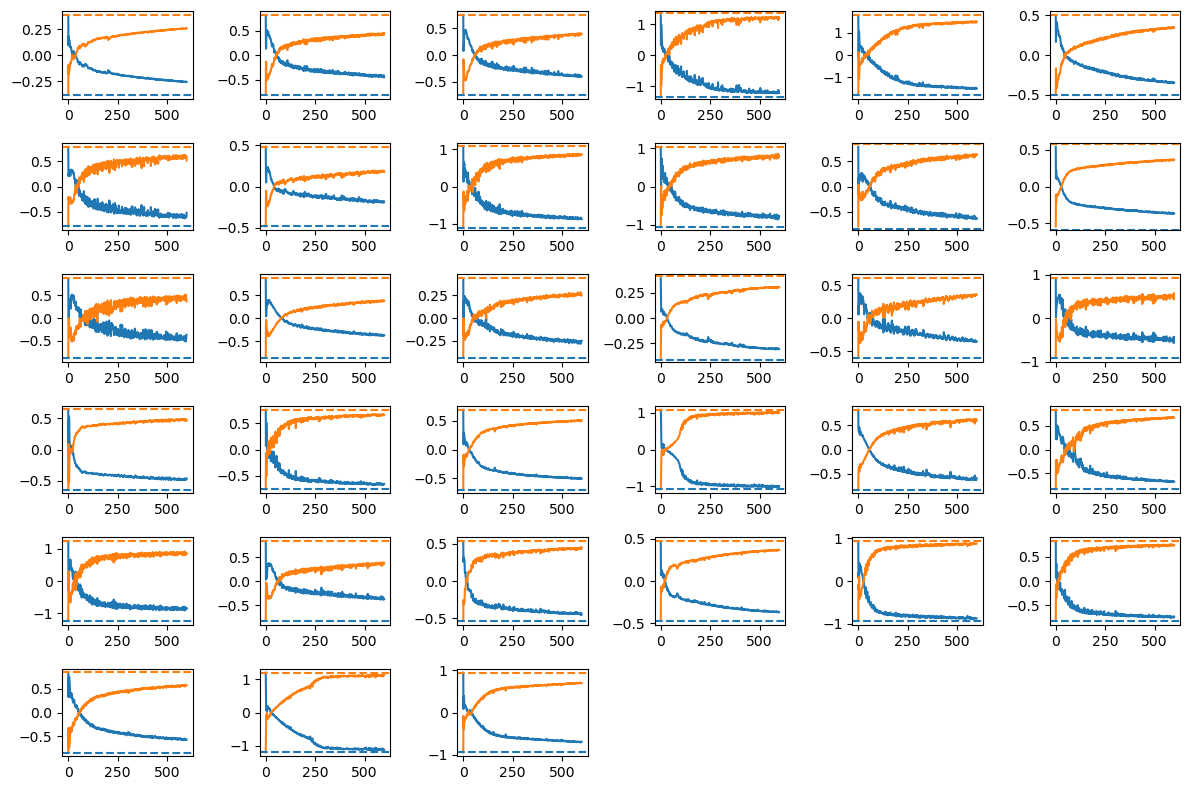

In [217]:
fx = 0
plt.figure(figsize=(12,8))
for fx in range(n_sessions):
    plt.subplot(6,6,fx+1)
    plt.plot(readout_history[fx][:,0])
    plt.plot(readout_history[fx][:,1])
    plt.axhline(readout_targets_by_session[fx][0],c='C0',linestyle='--')
    plt.axhline(readout_targets_by_session[fx][1],c='C1',linestyle='--')
plt.tight_layout()



## Simulate the retrained network

In [218]:
latent_activity_P1 = {}
latent_activity_A1 = {}

rnn.eval()
with torch.no_grad():
    for fx in session_ids:
        session = rnn.session_model(fx)
        # Reuse the saved initial observations; sample fresh input noise each call.
        activity = rnn(
            fx,
            initial_activity=session.readout_initial_activity,
        )
        latent_activity_P1[fx] = activity['P1'].T.cpu().numpy().copy()
        latent_activity_A1[fx] = activity['A1'].T.cpu().numpy().copy()


## CD dot product of data

In [219]:
cd2_by_session = {fx:[] for fx in session_ids}
for fx in session_ids:
    cd2_by_session[fx] = np.mean(latent_activity_P1[fx][:,12:16] - latent_activity_A1[fx][:,12:16],axis=1)

CDdotproduct_model = np.zeros(n_sessions)    
for fx in session_ids:
    CDdotproduct_model[fx] = np.inner(cd1_by_session[fx],cd2_by_session[fx]) / np.linalg.norm(cd1_by_session[fx]) / np.linalg.norm(cd2_by_session[fx])


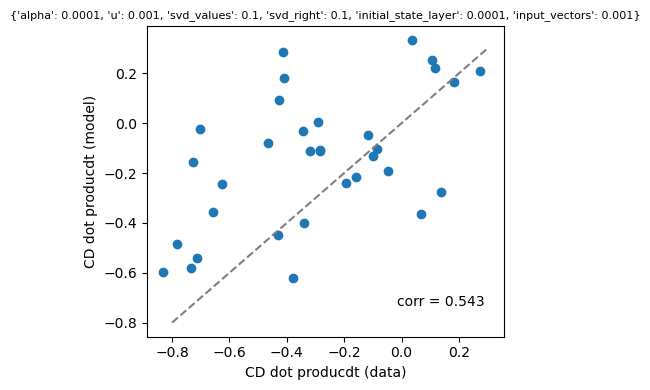

In [220]:
idline = np.linspace(-0.8,0.3)
plt.figure(figsize=(4.5,4))
_cor = np.corrcoef(CDdotproduct_data, CDdotproduct_model)[0,1]
plt.annotate('corr = ' + str(np.round(_cor,decimals=3)),xy=(0.7,0.1),xycoords='axes fraction')
plt.scatter(CDdotproduct_data, CDdotproduct_model)
plt.plot(idline,idline,c='gray',linestyle='--')
plt.xlabel('CD dot producdt (data)')
plt.ylabel('CD dot producdt (model)')
plt.title(str(learning_rates),fontsize=8)
plt.tight_layout()
# plt.savefig('./figure/learn2reverse/CDdotprod'+str(learning_rates)+'.png',dpi=300)


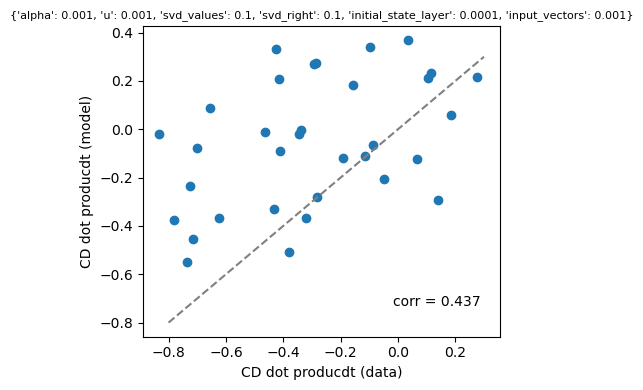

In [205]:
idline = np.linspace(-0.8,0.3)
plt.figure(figsize=(4.5,4))
_cor = np.corrcoef(CDdotproduct_data, CDdotproduct_model)[0,1]
plt.annotate('corr = ' + str(np.round(_cor,decimals=3)),xy=(0.7,0.1),xycoords='axes fraction')
plt.scatter(CDdotproduct_data, CDdotproduct_model)
plt.plot(idline,idline,c='gray',linestyle='--')
plt.xlabel('CD dot producdt (data)')
plt.ylabel('CD dot producdt (model)')
plt.title(str(learning_rates),fontsize=8)
plt.tight_layout()
plt.savefig('./figure/learn2reverse/CDdotprod'+str(learning_rates)+'.png',dpi=300)


# Dimensionality of recurrent weights

In [82]:
def find_effdim(_rnn):
    # Dictionaries accommodate the different neuron counts in each session.
    expvar_cumsum = {}
    components = {}

    for fx_idx in _rnn.session_ids:
        W = _rnn.recurrent_weight(fx_idx).detach().cpu().numpy()
        pca = PCA()
        pca.fit(W.T)
        expvar_cumsum[fx_idx] = np.cumsum(pca.explained_variance_ratio_)
        components[fx_idx] = pca.components_

    thr_effdim = 0.8
    effdim = np.array([
        int(np.argmax(values > thr_effdim) + 1)
        for fx_idx, values in expvar_cumsum.items()
    ])
    expvar_rank1 = np.array([expvar_cumsum[fx][0] for fx in range(_rnn.n_sessions)])

    print(effdim)
    print(f'sessions with dim <= 4: {np.sum(effdim<=4)}/{len(effdim)}')    
    
    return effdim, expvar_rank1, expvar_cumsum, components

In [83]:
effdim, expvar_rank1, _, _ = find_effdim(rnn)

[2 3 4 2 3 3 2 3 2 3 2 2 3 3 1 2 2 3 2 1 1 2 2 2 2 3 2 2 3 1 2 1 2]
sessions with dim <= 4: 33/33


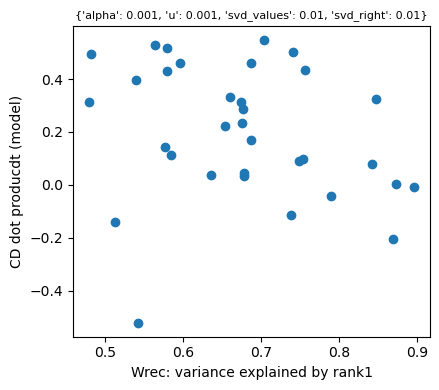

In [84]:
plt.figure(figsize=(4.5,4))
plt.scatter(expvar_rank1, CDdotproduct_model)
plt.xlabel('Wrec: variance explained by rank1')
plt.ylabel('CD dot producdt (model)')
plt.title(str(learning_rates),fontsize=8)
plt.tight_layout()


# Readout error


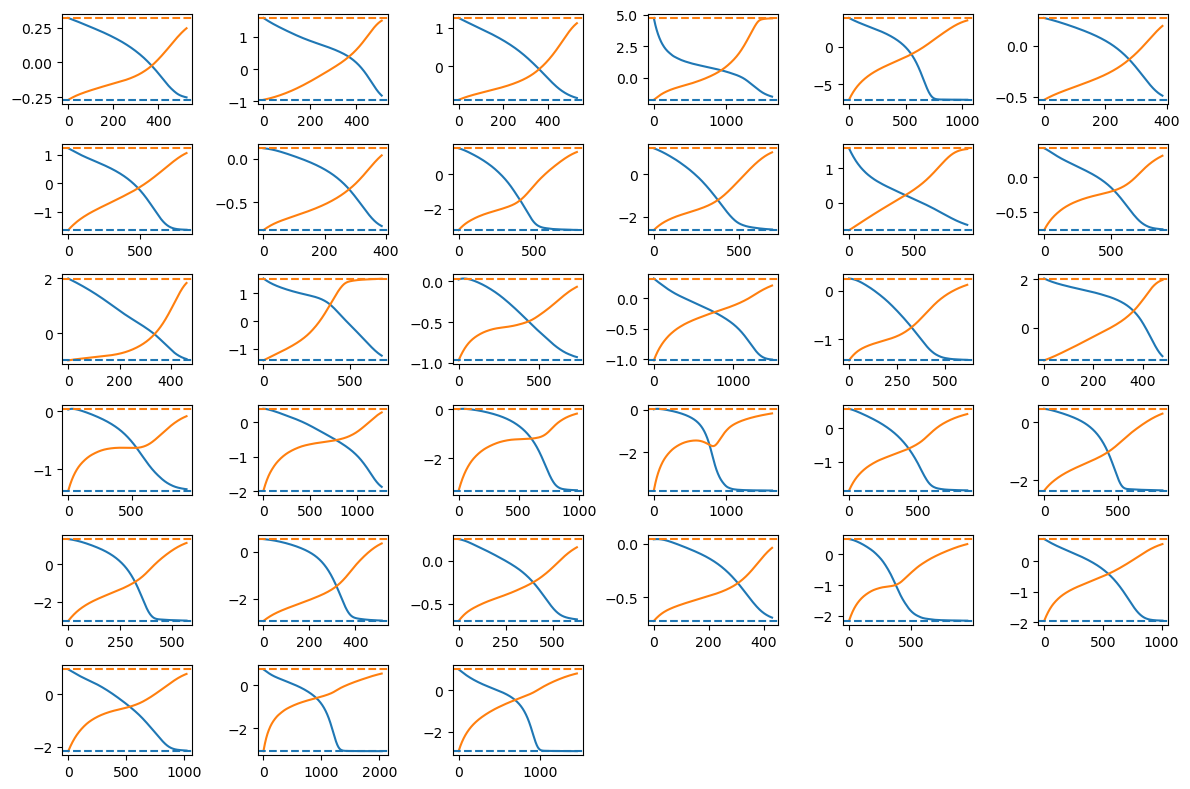

In [472]:
fx = 0
plt.figure(figsize=(12,8))
for fx in range(n_sessions):
    plt.subplot(6,6,fx+1)
    session_fx = rnn.session_model(fx)
    target_P2, target_A2 = session_fx.readout_targets.detach().cpu().numpy()
    readout_np = np.array(readout_history[fx])
    plt.plot(readout_np[:,0])
    plt.plot(readout_np[:,1])
    plt.axhline(target_P2,c='C0',linestyle='--')
    plt.axhline(target_A2,c='C1',linestyle='--')
plt.tight_layout()



## Get CD1 from the original network

Each saved `session.CD1` is the original model's P1 minus A1 population activity averaged over `[12:16]`, computed before retraining. These are the fixed, unnormalized vectors used to initialize `Vout` and define the retraining targets. `cd1_by_session[fx]` has shape `(units,)` for session `fx`.


In [473]:
cd1_by_session = {
    fx: rnn.session_model(fx).CD1.detach().cpu().numpy().copy()
    for fx in session_ids
}


## Simulate P1 and A1 for all sessions

Reuse each session's saved initial observations and input noise from retraining. The frozen initial-state layer and sensory/response inputs therefore receive the same drives used for the readout objective. P1/A1 label the input conditions here; their retrained readouts were called P2/A2 in the loss.

`latent_activity_P1[fx]` and `latent_activity_A1[fx]` contain NumPy arrays with shape `(units, time)`. Dictionaries preserve the actual session IDs and allow different unit counts across sessions.


In [474]:
latent_activity_P1 = {}
latent_activity_A1 = {}

with torch.no_grad():
    for fx in session_ids:
        session = rnn.session_model(fx)
        activity = rnn(
            fx,
            initial_activity=session.readout_initial_activity,
            input_timecourses=session.readout_input_timecourses,
        )
        latent_activity_P1[fx] = activity['P1'].T.cpu().numpy().copy()
        latent_activity_A1[fx] = activity['A1'].T.cpu().numpy().copy()


In [475]:
cd2_by_session = {fx:[] for fx in session_ids}
for fx in session_ids:
    cd2_by_session[fx] = np.mean(latent_activity_P1[fx][:,12:16] - latent_activity_A1[fx][:,12:16],axis=1)

CDdotproduct_model = np.zeros(n_sessions)    
CDdotproduct_model_nonnorm = np.zeros(n_sessions)    
for fx in session_ids:
    CDdotproduct_model[fx]         = np.inner(cd1_by_session[fx],cd2_by_session[fx]) / np.linalg.norm(cd1_by_session[fx]) / np.linalg.norm(cd2_by_session[fx])
    CDdotproduct_model_nonnorm[fx] = np.inner(cd1_by_session[fx],cd2_by_session[fx])

Vout_CD1_dotproduct = np.zeros(n_sessions)        
Vout_CD2_dotproduct = np.zeros(n_sessions)    
for fx in session_ids:
    Vout_CD1_dotproduct[fx] = np.inner(cd1_by_session[fx],vout_by_session[fx]) / np.linalg.norm(cd1_by_session[fx]) / np.linalg.norm(vout_by_session[fx])
    Vout_CD2_dotproduct[fx] = np.inner(cd2_by_session[fx],vout_by_session[fx]) / np.linalg.norm(cd2_by_session[fx]) / np.linalg.norm(vout_by_session[fx])
    


# Readout vs. CD1

In [522]:
vout_learned = {fx:[] for fx in range(n_sessions)}
for fx in range(n_sessions):
    vout_learned[fx] = vout_by_session[fx] - cd1_by_session[fx]

cd1_ortho = {fx:[] for fx in range(n_sessions)}
cd1_mod = {fx:[] for fx in range(n_sessions)}
cd1_coef = np.zeros(n_sessions)
for fx in range(n_sessions):
    cd1_fx        = cd1_by_session[fx] / np.linalg.norm(cd1_by_session[fx])
    cd1_coef[fx]  = np.inner(vout_learned[fx], cd1_fx)
    cd1_ortho[fx] = vout_learned[fx]   - cd1_coef[fx] * cd1_fx
    cd1_mod[fx]   = cd1_by_session[fx] + cd1_coef[fx] * cd1_fx
    # print(np.abs(np.inner(cd1_by_session[fx], cd1_ortho[fx]))<1e-5)

cd2_along_cd1 = np.zeros(n_sessions)
cd2_along_cd1_ortho = np.zeros(n_sessions)
for fx in range(n_sessions):
    cd2_along_cd1[fx]       = np.inner(cd1_mod[fx],   cd2_by_session[fx]) / np.linalg.norm(cd1_by_session[fx])**2
    cd2_along_cd1_ortho[fx] = np.inner(cd1_ortho[fx], cd2_by_session[fx]) / np.linalg.norm(cd1_by_session[fx])**2

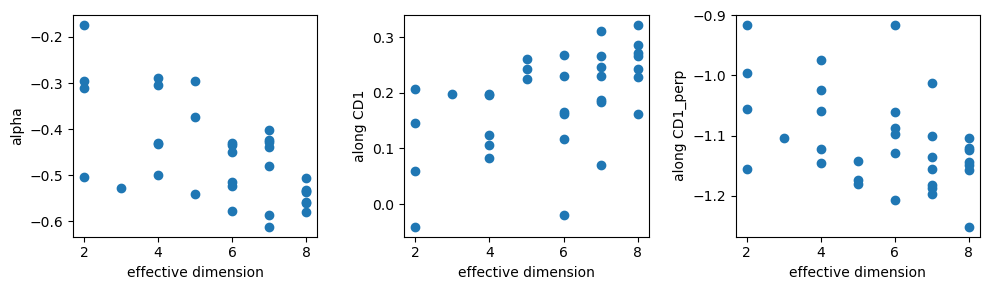

In [ ]:
idline = np.linspace(-10,0)
plt.figure(figsize=(10,3))
# plt.scatter(effdim_ctx1,CDdotproduct_model_nonnorm/cd1norm)
# plt.scatter(expvar_rank1_ctx1,CDdotproduct_model_nonnorm/cd1norm)
plt.subplot(131)
plt.scatter(effdim_ctx1,cd1_coef)
plt.xlabel('effective dimension')
plt.ylabel('alpha')
plt.subplot(132)
plt.scatter(effdim_ctx1,cd2_along_cd1)
plt.xlabel('effective dimension')
plt.ylabel('along CD1')
plt.subplot(133)
plt.scatter(effdim_ctx1,cd2_along_cd1_ortho)
plt.xlabel('effective dimension')
plt.ylabel('along CD1_perp')

plt.tight_layout()


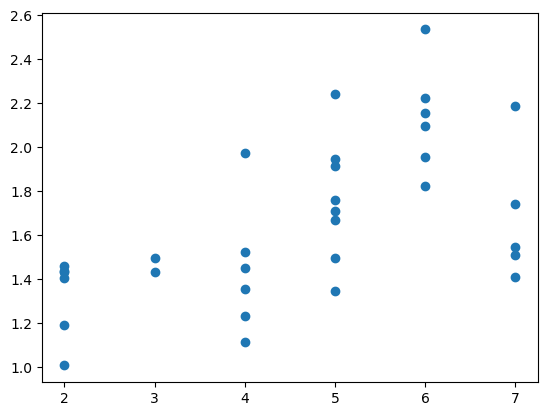

In [530]:
cd1_norm = np.array([np.linalg.norm(cd1_by_session[fx]) for fx in range(n_sessions)])
cd2_norm = np.array([np.linalg.norm(cd2_by_session[fx]) for fx in range(n_sessions)])
plt.figure()
plt.scatter(effdim, cd2_norm/cd1_norm)

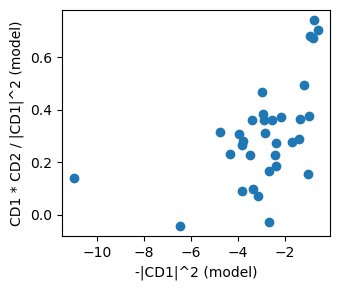

In [483]:
cd1norm = np.zeros(n_sessions)
for fx in range(n_sessions):
    cd1norm[fx] = np.linalg.norm(cd1_by_session[fx])**2
idline = np.linspace(-10,0)
plt.figure(figsize=(3.5,3))
plt.scatter(-cd1norm,CDdotproduct_model_nonnorm/cd1norm)
# plt.plot(idline,idline,c='gray',linestyle='--')
plt.xlabel('-|CD1|^2 (model)')
plt.ylabel('CD1 * CD2 / |CD1|^2 (model)')
plt.tight_layout()


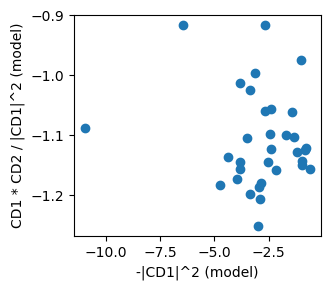

In [ ]:
plt.figure(figsize=(3.5,3))
# plt.scatter(-cd1norm,cd2_along_cd1)
plt.scatter(-cd1norm,cd2_along_cd1_ortho)
# plt.plot(idline,idline,c='gray',linestyle='--')
plt.xlabel('-|CD1|^2 (model)')
plt.ylabel('CD1 * CD2 / |CD1|^2 (model)')
plt.tight_layout()


Text(0.5, 1.0, 'corr 0.328')

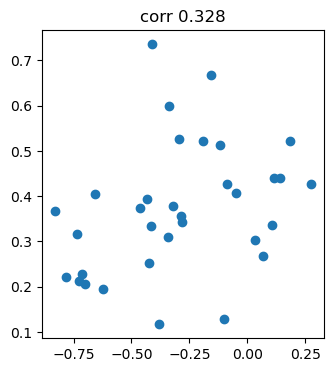

In [442]:
plt.figure(figsize=(8,4))
plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,CDdotproduct_model_nonnorm/cd1norm)[0,1]
plt.scatter(CDdotproduct_data,CDdotproduct_model_nonnorm/cd1norm)
# _cor = np.corrcoef(CDdotproduct_data,-cd1norm)[0,1]
# plt.scatter(CDdotproduct_data,-cd1norm)

plt.title(f'corr {np.round(_cor,decimals=3)}')

Text(0, 0.5, 'eff dim of retrained model')

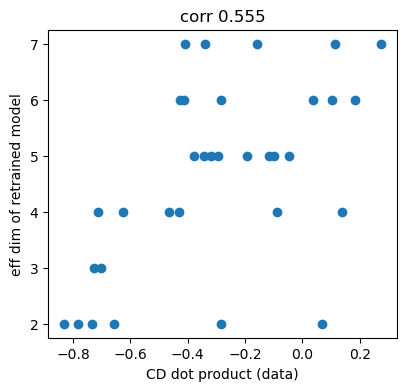

In [465]:
plt.figure(figsize=(4.5,4))
# plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,effdim)[0,1]
plt.scatter(CDdotproduct_data,effdim)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('eff dim of retrained model')

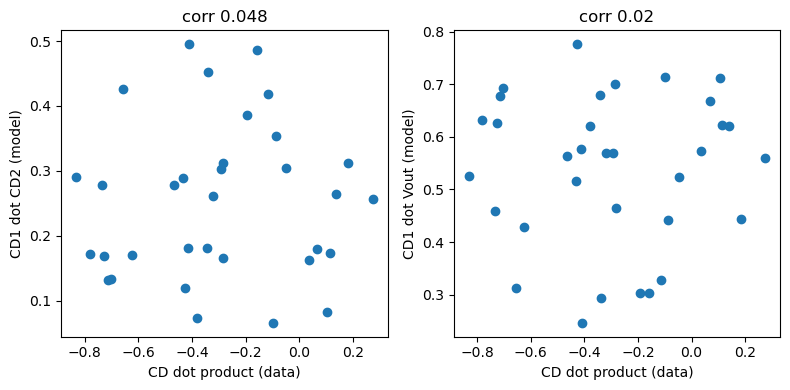

In [443]:
    
idline = np.linspace(-0.8,0.2)
plt.figure(figsize=(8,4))
plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,CDdotproduct_model)[0,1]
plt.scatter(CDdotproduct_data,CDdotproduct_model)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot CD2 (model)')
# plt.xlim([-0.9,0.3])
# plt.ylim([-0.5,0.0])
plt.subplot(122)
_cor = np.corrcoef(CDdotproduct_data,Vout_CD1_dotproduct)[0,1]
plt.scatter(CDdotproduct_data,Vout_CD1_dotproduct)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot Vout (model)')
plt.tight_layout()


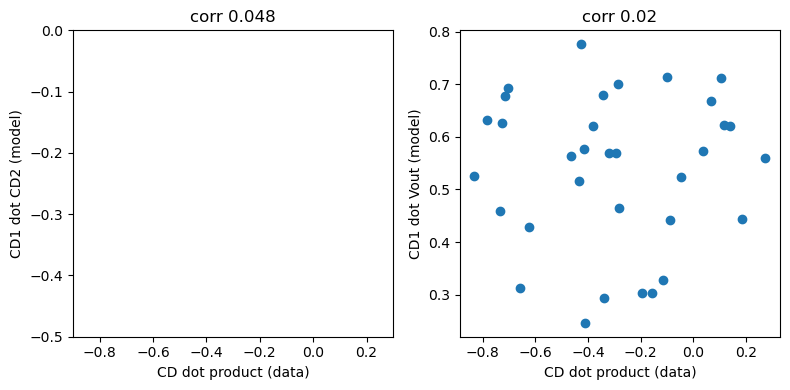

In [444]:
idline = np.linspace(-0.8,0.2)
plt.figure(figsize=(8,4))
plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,CDdotproduct_model)[0,1]
plt.scatter(CDdotproduct_data,CDdotproduct_model)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot CD2 (model)')
plt.xlim([-0.9,0.3])
plt.ylim([-0.5,0.0])
plt.subplot(122)
_cor = np.corrcoef(CDdotproduct_data,Vout_CD1_dotproduct)[0,1]
plt.scatter(CDdotproduct_data,Vout_CD1_dotproduct)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot Vout (model)')
plt.tight_layout()


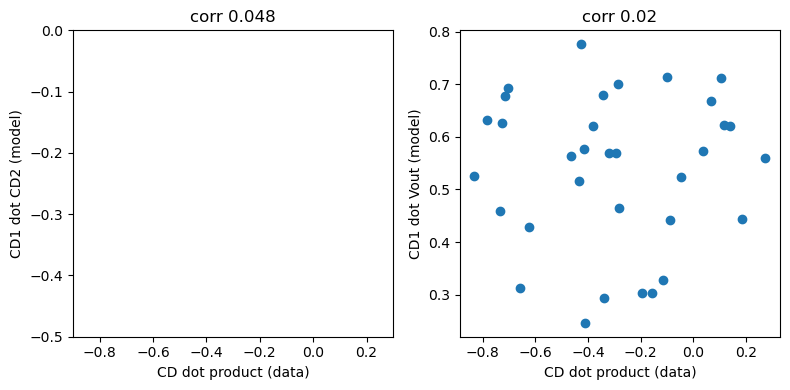

In [445]:
idline = np.linspace(-0.8,0.2)
plt.figure(figsize=(8,4))
plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,CDdotproduct_model)[0,1]
plt.scatter(CDdotproduct_data,CDdotproduct_model)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot CD2 (model)')
plt.xlim([-0.9,0.3])
plt.ylim([-0.5,0.0])
plt.subplot(122)
_cor = np.corrcoef(CDdotproduct_data,Vout_CD1_dotproduct)[0,1]
plt.scatter(CDdotproduct_data,Vout_CD1_dotproduct)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot Vout (model)')
plt.tight_layout()


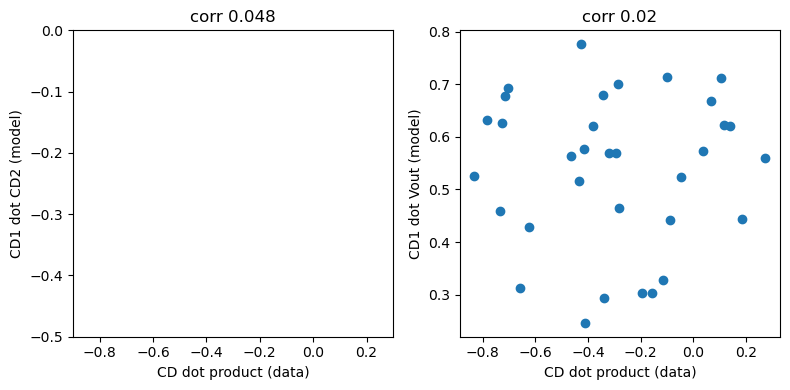

In [446]:
idline = np.linspace(-0.8,0.2)
plt.figure(figsize=(8,4))
plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,CDdotproduct_model)[0,1]
plt.scatter(CDdotproduct_data,CDdotproduct_model)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot CD2 (model)')
plt.xlim([-0.9,0.3])
plt.ylim([-0.5,0.0])
plt.subplot(122)
_cor = np.corrcoef(CDdotproduct_data,Vout_CD1_dotproduct)[0,1]
plt.scatter(CDdotproduct_data,Vout_CD1_dotproduct)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot Vout (model)')
plt.tight_layout()


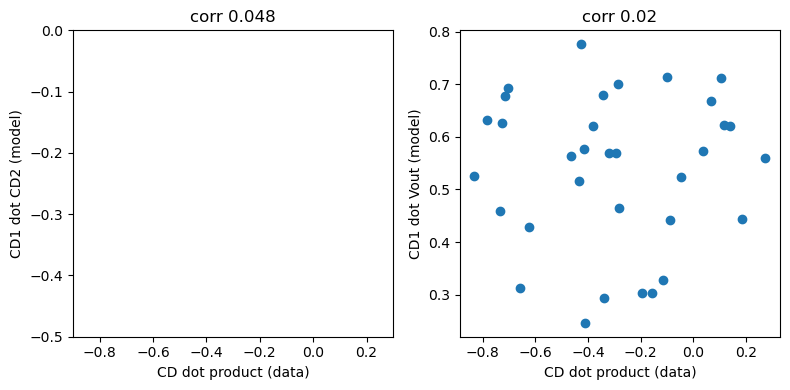

In [447]:
idline = np.linspace(-0.8,0.2)
plt.figure(figsize=(8,4))
plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,CDdotproduct_model)[0,1]
plt.scatter(CDdotproduct_data,CDdotproduct_model)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot CD2 (model)')
plt.xlim([-0.9,0.3])
plt.ylim([-0.5,0.0])
plt.subplot(122)
_cor = np.corrcoef(CDdotproduct_data,Vout_CD1_dotproduct)[0,1]
plt.scatter(CDdotproduct_data,Vout_CD1_dotproduct)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot Vout (model)')
plt.tight_layout()


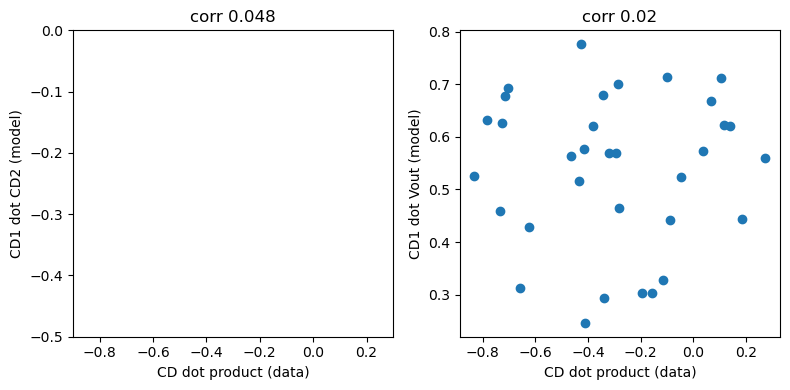

In [448]:
idline = np.linspace(-0.8,0.2)
plt.figure(figsize=(8,4))
plt.subplot(121)
_cor = np.corrcoef(CDdotproduct_data,CDdotproduct_model)[0,1]
plt.scatter(CDdotproduct_data,CDdotproduct_model)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot CD2 (model)')
plt.xlim([-0.9,0.3])
plt.ylim([-0.5,0.0])
plt.subplot(122)
_cor = np.corrcoef(CDdotproduct_data,Vout_CD1_dotproduct)[0,1]
plt.scatter(CDdotproduct_data,Vout_CD1_dotproduct)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('CD dot product (data)')
plt.ylabel('CD1 dot Vout (model)')
plt.tight_layout()


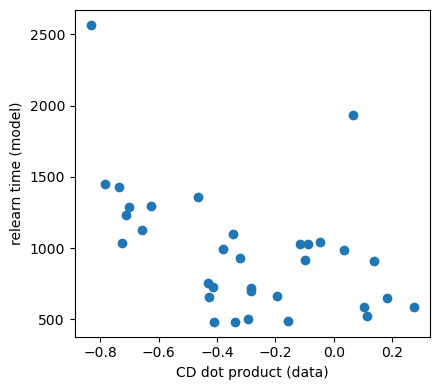

In [449]:
plt.figure(figsize=(4.5,4))
plt.scatter(CDdotproduct_data, steps_to_tolerance)
plt.xlabel('CD dot product (data)')
plt.ylabel('relearn time (model)')
plt.tight_layout()

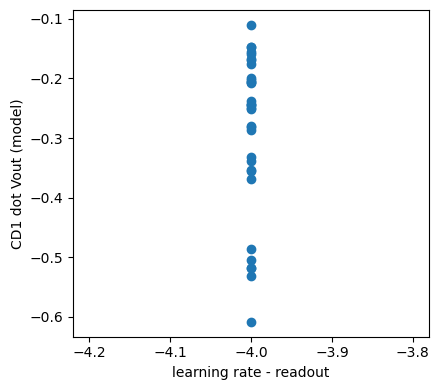

In [450]:
plt.figure(figsize=(4.5,4))
plt.scatter(np.log10(readout_lr_by_session), np.log10(Vout_CD1_dotproduct))
plt.xlabel('learning rate - readout')
plt.ylabel('CD1 dot Vout (model)')
plt.tight_layout()